# 08 · Vector autoregression and Granger causality

The simulated system mimics a store (all series are stationary deviations from normal levels):

```
ads(t-1)       → visitors(t)
visitors(t-1)  → purchases(t)
price(t-1)     → purchases(t)     (negative)
purchases(t-2) → price(t)         (feedback: pricing reacts to sales)
```

**Granger causality:** $x$ Granger-causes $y$ if past $x$ improves the forecast of $y$ beyond what past $y$
(and the other variables) already provide. It is *predictive* causality. It coincides with real causation
only if all common causes are in the system and effects take at least one time step.

**You will implement:** VAR(p) estimation by OLS, AIC lag selection, Granger F-tests, and impulse responses.

**Library check:** `statsmodels.tsa.api.VAR`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.api import VAR

import causalsim as cs
from causalsim.plotting import use_style

use_style()

sim = cs.var_system(n=1_000, seed=0)
df = sim.data
names = list(df.columns)
k = len(names)
print(sim)
print("true cross-variable links:", sorted(sim.truth["links"]))

SimResult(n=1000, cols=['visitors', 'price', 'purchases', 'ads'], truth={links={('visitors', 'purchases', 1), ('purchases', 'price', 2), ('price', 'purchases', 1), ('ads', 'visitors', 1)}, coef_matrices=array(2, 4, 4), max_lag=2})
true cross-variable links: [('ads', 'visitors', 1), ('price', 'purchases', 1), ('purchases', 'price', 2), ('visitors', 'purchases', 1)]


## 1. From scratch: VAR(p) by OLS

Stack the regressors $x_t = [1, y_{t-1}^\top, \dots, y_{t-p}^\top]^\top$ and regress every variable on the same
$x_t$. Equation-by-equation OLS is efficient here because all equations share regressors.

In [2]:
def lag_matrix(Y, p, start=None):
    """Rows t = start..T-1, columns [1, y_{t-1}, ..., y_{t-p}]. start defaults to p."""
    start = p if start is None else start
    T = len(Y)
    cols = [np.ones(T - start)] + [Y[start - l : T - l] for l in range(1, p + 1)]
    return np.column_stack(cols), Y[start:]


def fit_var(Y, p, start=None):
    X, Yt = lag_matrix(Y, p, start)
    B = np.linalg.lstsq(X, Yt, rcond=None)[0]  # (1 + k p) × k
    E = Yt - X @ B
    return B, E, X, Yt


Yall = df.to_numpy()
p = 2
B, E, Xlag, Yt = fit_var(Yall, p)
A_hat = B[1:].reshape(p, k, k).transpose(0, 2, 1)  # A_hat[l][effect, cause]
print("max |estimated − true| coefficient:", np.abs(A_hat - sim.truth["coef_matrices"]).max().round(3))

res = VAR(df).fit(p)
np.testing.assert_allclose(B, res.params.to_numpy(), atol=1e-10)
print("✓ VAR coefficients match statsmodels")

max |estimated − true| coefficient: 0.071
✓ VAR coefficients match statsmodels


## 2. From scratch: lag selection by AIC
$\text{AIC}(p) = \log\det\hat\Sigma_p + \frac{2\,(k^2 p + k)}{T}$, with $\hat\Sigma_p = E^\top E / T$. Every candidate $p$ must be fit on the
**same sample** (drop the first `maxlags` rows for all of them), or the criteria aren't comparable.

In [3]:
def select_lag_aic(Y, maxlags):
    aics = {}
    for pp in range(0, maxlags + 1):
        if pp == 0:
            Yt_ = Y[maxlags:]
            E_ = Yt_ - Yt_.mean(axis=0)
        else:
            _, E_, _, _ = fit_var(Y, pp, start=maxlags)
        T_ = len(E_)
        sigma = E_.T @ E_ / T_
        aics[pp] = np.log(np.linalg.det(sigma)) + 2 * (k * k * pp + k) / T_
    return min(aics, key=aics.get), aics


p_aic, aics = select_lag_aic(Yall, maxlags=8)
p_sm = VAR(df).select_order(maxlags=8).aic
assert p_aic == p_sm
print(f"AIC picks p = {p_aic} (statsmodels agrees; true max lag = {sim.truth['max_lag']})")

AIC picks p = 2 (statsmodels agrees; true max lag = 2)


## 3. From scratch: Granger causality F-test

For the equation of `effect`, compare the full model with one that drops all $p$ lags of `cause`:
$F = \dfrac{(\text{RSS}_r - \text{RSS}_u)/p}{\text{RSS}_u/(T - (1 + kp))}$, with $F \sim F(p,\,T-1-kp)$ under $H_0$.

In [4]:
def granger_f(Y, names, cause, effect, p):
    X, Yt = lag_matrix(Y, p)
    c, e = names.index(cause), names.index(effect)
    drop = [1 + l * len(names) + c for l in range(p)]
    keep = [j for j in range(X.shape[1]) if j not in drop]
    rss = lambda XX: np.sum((Yt[:, e] - XX @ np.linalg.lstsq(XX, Yt[:, e], rcond=None)[0]) ** 2)
    rss_u, rss_r = rss(X), rss(X[:, keep])
    df2 = len(Yt) - X.shape[1]
    F = ((rss_r - rss_u) / p) / (rss_u / df2)
    return F, stats.f.sf(F, p, df2)


F, pval = granger_f(Yall, names, "price", "purchases", p)
sm_test = res.test_causality("purchases", ["price"], kind="f")
np.testing.assert_allclose(F, sm_test.test_statistic, rtol=1e-8)
print(f"price → purchases: F = {F:.1f}, p = {pval:.2e}")
print(f"statsmodels: same F, but df = {sm_test.df} → p = {sm_test.pvalue:.2e}")
print("✓ F statistic matches statsmodels")

price → purchases: F = 398.9, p = 9.24e-128
statsmodels: same F, but df = (2, 3956) → p = 1.50e-158
✓ F statistic matches statsmodels


Same statistic, different p-value: statsmodels' system-wide Wald test uses denominator degrees of freedom
$k\,(T - 1 - kp)$ instead of $T - 1 - kp$. The difference is irrelevant here and matters only in short series.
Always check *which* test a library runs.

### The full Granger matrix

In [5]:
pmat = pd.DataFrame(index=names, columns=names, dtype=float)
for c in names:
    for e in names:
        if c != e:
            pmat.loc[c, e] = granger_f(Yall, names, c, e, p)[1]
true_pairs = {(c, e) for c, e, _ in sim.truth["links"]}
found = {(c, e) for c in names for e in names if c != e and pmat.loc[c, e] < 0.01}
print("rows = cause, columns = effect; p-values:")
display(pmat.map(lambda v: "" if np.isnan(v) else f"{v:.1e}"))
print("missed:", true_pairs - found or "none", "| spurious:", found - true_pairs or "none")

rows = cause, columns = effect; p-values:


,visitors,price,purchases,ads
visitors,,5.4e-01,1.4e-88,1.0e+00
price,6.7e-01,,9.2e-128,7.6e-01
purchases,7.9e-01,6.0e-38,,9.3e-01
ads,1.9e-137,7.5e-01,2.5e-01,


missed: none | spurious: none


## 4. From scratch: impulse responses

Write the VAR in moving-average form: $\Phi_0 = I$, $\Phi_h = \sum_{l=1}^{p} A_l\,\Phi_{h-l}$.
$\Phi_h[i,j]$ is the response of variable $i$, $h$ steps after a unit shock to variable $j$. These are
non-orthogonalized responses; orthogonalized (Cholesky) responses depend on the variable ordering, which is a
causal assumption in disguise.

✓ impulse responses match statsmodels


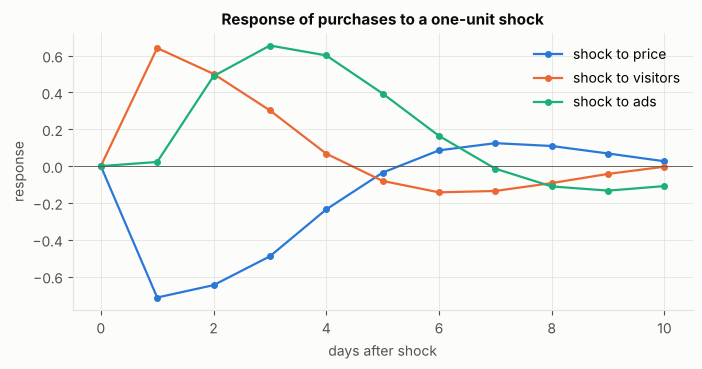

In [6]:
def irf(A, horizon):
    p_, k_, _ = A.shape
    Phi = [np.eye(k_)]
    for h in range(1, horizon + 1):
        Phi.append(sum(A[l] @ Phi[h - l - 1] for l in range(min(p_, h))))
    return np.array(Phi)


Phi = irf(A_hat, 10)
np.testing.assert_allclose(Phi, res.irf(10).irfs, atol=1e-10)
print("✓ impulse responses match statsmodels")

fig, ax = plt.subplots()
for cause in ("price", "visitors", "ads"):
    ax.plot(Phi[:, names.index("purchases"), names.index(cause)], marker="o", markersize=4, label=f"shock to {cause}")
ax.axhline(0, color="#52514e", linewidth=0.6)
ax.set(title="Response of purchases to a one-unit shock", xlabel="days after shock", ylabel="response")
ax.legend()
plt.show()

## 5. Break it

**(a) Omitted mediator.** Drop `visitors`. `ads` now appears to Granger-cause `purchases` directly, with lag 2.
That's correct as *prediction* and misleading as a mechanism.

**(b) Same-day effects.** In daily data the price response is often same-day. Granger tests look only at lags,
so a purely contemporaneous effect is invisible.

In [7]:
sub = df[["ads", "price", "purchases"]].to_numpy()
F_a, p_a = granger_f(sub, ["ads", "price", "purchases"], "ads", "purchases", p=3)
print(f"(a) without visitors: ads → purchases  F = {F_a:.1f}, p = {p_a:.1e}   (no direct link exists)")

rng = np.random.default_rng(1)
n = 2_000
price = rng.normal(size=n)
purchases = -0.8 * price + rng.normal(size=n)  # effect at lag 0 only
Fb, pb = granger_f(np.column_stack([price, purchases]), ["price", "purchases"], "price", "purchases", p=2)
print(f"(b) same-day effect of −0.8: Granger p = {pb:.2f}, so the test finds nothing")

(a) without visitors: ads → purchases  F = 103.4, p = 3.3e-58   (no direct link exists)
(b) same-day effect of −0.8: Granger p = 0.88, so the test finds nothing


**Exercises**
1. Use tigramite's PCMCI+ (`pip install tigramite`) on the same data. It handles contemporaneous links and conditions
   on the right variables automatically. Does it recover the true graph, including case (b)?
2. Make the system non-stationary (a random walk in `price`) and rerun the Granger tests in levels vs. first differences.
3. Compute orthogonalized IRFs with two different variable orderings. How different are they, and why?